<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="40"/>

# AIFS et IFS côte à côte sur le Sénégal 🤖
### Données ouvertes et gratuites de l'ECMWF · apprentissage automatique et physique · sans compte
*Réalisé pour SEWA (Strengthening Early Warnings for Africa), le renforcement des alertes précoces en Afrique*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/aifs_vs_ifs_fr.ipynb)

L'ECMWF produit deux prévisions mondiales, toutes deux en **données ouvertes** : l'**IFS**, fondé sur la physique,
et l'**AIFS**, le modèle par apprentissage automatique, qui calcule une prévision à dix jours en quelques minutes. Ce
notebook prend le même run des deux, cartographie côte à côte la température à 2 m à environ deux jours et demi
d'échéance, puis la différence entre les deux.

**Ce qu'il vous faut :** un compte Google (pour utiliser Colab). Aucun autre compte, aucun frais, rien à installer. Tout tourne sur les ordinateurs de Google : les données y sont téléchargées, pas sur votre
téléphone ou votre ordinateur, donc une connexion lente ou mobile suffit.

| Données | Ce que ce notebook utilise | Licence |
|---|---|---|
| Prévision IFS de l'ECMWF, 0,25° | Température à 2 m, dernier run | CC BY 4.0, données ouvertes |
| Prévision AIFS Single de l'ECMWF, 0,25° | Température à 2 m, le même run | CC BY 4.0, données ouvertes |

**Outils :** [earthkit](https://earthkit.ecmwf.int), les outils Python libres et gratuits de l'ECMWF pour les données météo et climat.

*Cliquez sur **Exécution → Tout exécuter** (Runtime → Run all). La première exécution prend quelques minutes, surtout pour installer les outils.*

In [ ]:
# Installer les outils libres (Colab / nouvelle machine). Environ 1 minute.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # à importer avant earthkit.data (évite un plantage à la fermeture)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
MOIS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "septembre", "octobre",
        "novembre", "décembre"]
def jour(d): return f"{JOURS[d.weekday()]} {d.day} {MOIS[d.month - 1]}"     # dates en français
def date(d): return f"{d.day} {MOIS[d.month - 1]} {d.year}"

## 1 · Choisir la zone et l'échéance

In [3]:
AREA = [22.0, -22.0, 8.0, -6.0]             # nord, ouest, sud, est
STEP = 60                                   # heures après le début du run (environ deux jours et demi)
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Télécharger les deux prévisions (données ouvertes de l'ECMWF, 0,25°)

In [4]:
def get(model):
    for source in ("ecmwf", "aws", "google"):  # l'ECMWF d'abord, puis les miroirs cloud s'il est occupé
        try:
            fl = ekd.from_source("ecmwf-open-data", source=source, model=model, param="2t", step=STEP).to_fieldlist()
            break
        except Exception as err:
            print(f"{source} ne répond pas ({type(err).__name__}), essai du miroir suivant")
    x = fl.to_xarray()
    x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
    x = x.sel(latitude=slice(AREA[0], AREA[2]), longitude=slice(AREA[1], AREA[3]))
    return fl, x[list(x.data_vars)[0]].squeeze() - 273.15

ifs_fl, ifs = get("ifs")
aifs_fl, aifs = get("aifs-single")
run, valid = ifs_fl[0].time.base_datetime(), ifs_fl[0].time.valid_datetime()
assert aifs_fl[0].time.base_datetime() == run, "les deux modèles viennent de runs différents : relancez la cellule"
diff = aifs - ifs
print(f"Run du {date(run)} à {run:%H} h UTC, valable le {jour(valid)} à {valid:%H} h UTC")
print(f"IFS de {float(ifs.min()):.0f} à {float(ifs.max()):.0f} °C · AIFS de {float(aifs.min()):.0f} à {float(aifs.max()):.0f} °C")
print(f"AIFS moins IFS : moyenne {float(diff.mean()):+.1f} °C, écart typique {float(np.sqrt((diff ** 2).mean())):.1f} °C")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Run du 19 novembre 2026 à 06 h UTC, valable le samedi 21 novembre à 18 h UTC
IFS de 22 à 36 °C · AIFS de 23 à 38 °C
AIFS moins IFS : moyenne +0.6 °C, écart typique 1.2 °C


## 3 · Les cartographier

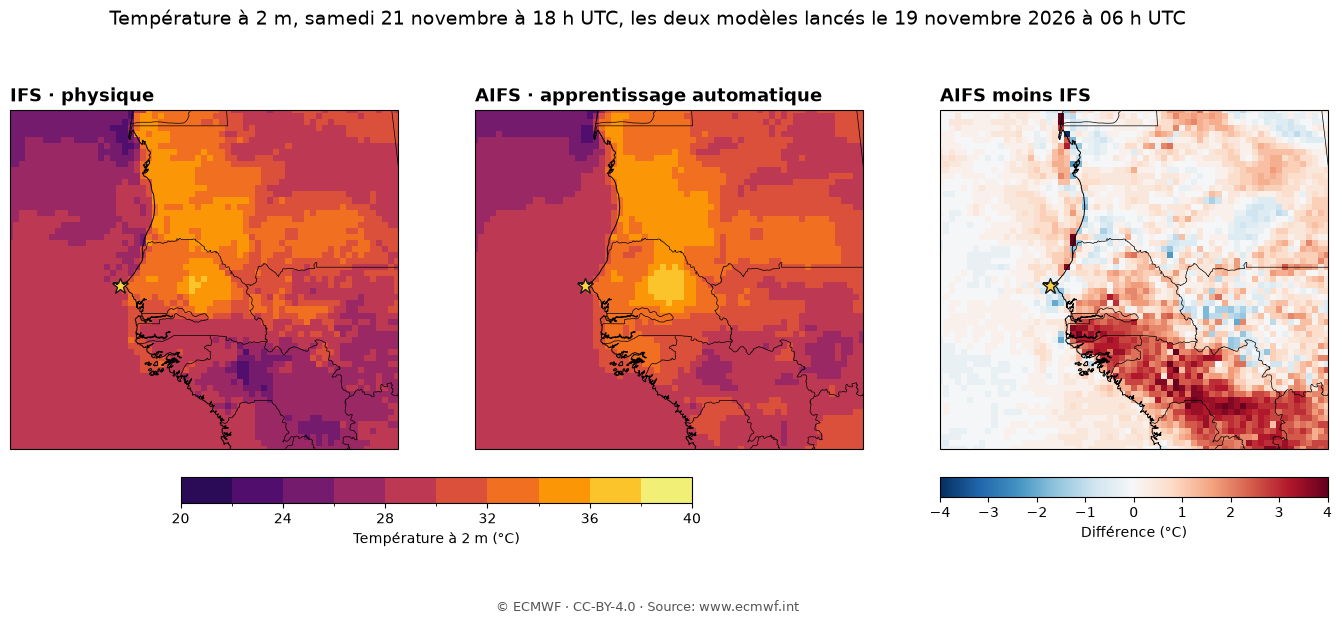

In [5]:
from matplotlib.colors import BoundaryNorm, ListedColormap
levels = [20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]
cmap = ListedColormap(plt.get_cmap("inferno")(np.linspace(0.15, 0.95, len(levels) - 1)))
fig, axs = plt.subplots(1, 3, figsize=(17, 6.2), subplot_kw=dict(projection=ccrs.PlateCarree()))
for ax, da, title in ((axs[0], ifs, "IFS · physique"), (axs[1], aifs, "AIFS · apprentissage automatique")):
    m = ax.pcolormesh(da.longitude, da.latitude, da, cmap=cmap, norm=BoundaryNorm(levels, cmap.N))
    ax.set_title(title, fontsize=13, fontweight="bold", loc="left")
fig.colorbar(m, ax=axs[:2], orientation="horizontal", shrink=0.6, pad=0.06, label="Température à 2 m (°C)")
d = axs[2].pcolormesh(diff.longitude, diff.latitude, diff, cmap="RdBu_r", vmin=-4, vmax=4)
axs[2].set_title("AIFS moins IFS", fontsize=13, fontweight="bold", loc="left")
fig.colorbar(d, ax=axs[2], orientation="horizontal", pad=0.06, label="Différence (°C)")
for ax in axs:
    ax.set_extent([AREA[1], AREA[3], AREA[2], AREA[0]]); ax.coastlines(lw=0.7); ax.add_feature(__import__("cartopy").feature.BORDERS, lw=0.5)
    ax.plot(-17.467, 14.716, "*", ms=12, color="#ffd23f", mec="#1a1a1a", transform=ccrs.PlateCarree())
fig.suptitle(f"Température à 2 m, {jour(valid)} à {valid:%H} h UTC, les deux modèles lancés le {date(run)} à {run:%H} h UTC", fontsize=14)
fig.text(0.5, 0.01, "© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int", ha="center", fontsize=9, color="#555")
fig.savefig("aifs_vs_ifs_fr.png", dpi=110, bbox_inches="tight")
plt.show()

## 4 · À vous de jouer 🌍

- **Plus loin :** `STEP = 144` (six jours). Les deux modèles s'écartent en général avec l'échéance.
- **Une autre variable :** `param="10u"` ou `"msl"` (pression au niveau de la mer ; divisez par 100 pour des hPa).
- **Les ensembles :** les deux ont aussi des ensembles ouverts : `model="aifs-ens"` ou `"ifs"` avec `stream="enfo"`.

### Données et licence
Les données ouvertes de l'ECMWF sont gratuites sous licence **Creative Commons CC-BY-4.0** :
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. Sans compte, sans clé.

[Données ouvertes de l'ECMWF](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)